# Analisis CDEA — Bab IV

**Main Study dan Small-Model Extension** · *Baseline* vs *Proposed* · 32 tugas OpenApps.

## 00 — Persiapan Dataset dan Konfigurasi

Membaca 2 arsip sumber, membentuk data pasangan valid, dan menyiapkan fungsi analisis. Data sumber tidak dimodifikasi.

In [32]:
from pathlib import Path
from collections import Counter
import io, json, zipfile, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display

MAIN_ZIP = 'main_observation.zip'
SCALE_ZIP = 'scale_reference.zip'
BOOTSTRAPS = 4000
SEED = 233
ROOT = Path('hasil_analisis_cdea')
FIG = ROOT / 'figures'
TAB = ROOT / 'tables'
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
TABLES, FIGURES = {}, []

pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 155)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 190, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Palet warna yang konsisten di seluruh grafik.
WARNA_BASELINE = '#4C78A8'   # biru
WARNA_PROPOSED = '#59A14F'   # hijau
WARNA_LARGE = '#B07AA1'      # ungu lembut
WARNA_SMALL = '#F28E2B'      # oranye
WARNA_TAMBAHAN_1 = '#76B7B2' # teal
WARNA_TAMBAHAN_2 = '#E15759' # merah lembut
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[WARNA_BASELINE, WARNA_PROPOSED, WARNA_SMALL, WARNA_LARGE, WARNA_TAMBAHAN_1, WARNA_TAMBAHAN_2])


def _manifest_in_zip(z):
    roots = [p for p in z.namelist() if p.endswith('manifest.json') and p.count('/') <= 1]
    if len(roots) != 1:
        raise ValueError('Expected one manifest.json at the ZIP root or one directory below it')
    path = roots[0]
    return path[:-len('manifest.json')], json.loads(z.read(path))


def find_archive(protocol, explicit=''):
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if not path.is_file(): raise FileNotFoundError(path)
        return path
    # Prefer notebook working directory; only look in fallback locations if missing.
    for folder in (Path.cwd(), Path('/content')):
        if not folder.is_dir(): continue
        matches = []
        for p in sorted(set(p.resolve() for p in folder.glob('*.zip'))):
            try:
                with zipfile.ZipFile(p) as z:
                    _, m = _manifest_in_zip(z)
                    if m.get('protocol') == protocol: matches.append(p)
            except (OSError, ValueError, KeyError, zipfile.BadZipFile):
                continue
        if len(matches) > 1:
            raise ValueError(f'Multiple {protocol} inputs: {matches}; set MAIN_ZIP or SCALE_ZIP explicitly')
        if matches:return matches[0]
    return None


import shutil

# Paket dataset opsional: ekstraksi hanya 2 arsip sumber (tanpa membuka isi episode).
DATASET_PAKET = ''  # Paket opsional: Dataset_CDEA.zip

def siapkan_dataset():
    if DATASET_PAKET:
        kandidat = [Path(DATASET_PAKET).expanduser()]
    else:
        kandidat = [p for folder in (Path.cwd(), Path('/content')) if folder.is_dir()
                    for p in sorted(folder.glob('Dataset_CDEA*.zip'))]
    for paket in kandidat:
        if not paket.is_file():
            continue
        with zipfile.ZipFile(paket) as z:
            if 'DATASET_CDEA.json' not in z.namelist():
                continue
            identitas = json.loads(z.read('DATASET_CDEA.json'))
            for sumber in identitas['files']:
                nama = sumber['nama']
                if Path(nama).name != nama or nama not in z.namelist():
                    raise ValueError('Nama arsip sumber tidak sesuai dengan paket dataset')
                tujuan = Path.cwd() / nama
                if not tujuan.exists():
                    with z.open(nama) as asal, tujuan.open('wb') as hasil:
                        shutil.copyfileobj(asal, hasil)
                hash_aktual = hashlib.sha256(tujuan.read_bytes()).hexdigest()
                if hash_aktual != sumber['sha256']:
                    raise ValueError(f'SHA-256 tidak sesuai: {nama}')
            print('Dataset tersedia:', ', '.join(x['nama'] for x in identitas['files']))
            return
    if DATASET_PAKET:
        raise FileNotFoundError('Paket dataset tidak ditemukan: '+DATASET_PAKET)

def as_bool(s):
    out = s.astype('string').str.strip().str.lower().map(
        {'true': True, 'false': False, '1': True, '0': False})
    return out.astype('boolean')


def study_from_zip(path, protocol):
    if path is None: return None
    with zipfile.ZipFile(path) as z:
        prefix, manifest = _manifest_in_zip(z)
        if manifest.get('protocol') != protocol:
            raise ValueError(f'Unexpected protocol: {manifest.get("protocol")}; expected {protocol}')
        pairs = pd.read_csv(io.BytesIO(z.read(prefix + 'pairs.csv')), encoding='utf-8-sig')
        episodes = pd.read_csv(io.BytesIO(z.read(prefix + 'results.csv')), encoding='utf-8-sig')
    pairs.columns = pairs.columns.str.lstrip('\ufeff')
    episodes.columns = episodes.columns.str.lstrip('\ufeff')
    for field in ('paired_valid', 'baseline_success', 'proposed_success'):
        pairs[field] = as_bool(pairs[field])
    for field in ('official_success_raw', 'paired_analysis_success', 'episode_valid', 'analysis_included'):
        if field in episodes: episodes[field] = as_bool(episodes[field])
    scheduled = int(manifest['planned_pairs'])
    if len(pairs) != scheduled or len(manifest.get('pairs', [])) != scheduled:
        raise ValueError('Scheduled pair count conflicts with manifest or pairs.csv')
    if len(episodes) > int(manifest['planned_episodes']):
        raise ValueError('More episodes than the declared schedule')
    if pairs.pair_id.duplicated().any() or episodes.duplicated(['pair_id','method']).any():
        raise ValueError('Duplicate pair_id or episode (pair_id,method) slot')
    if set(pairs.pair_id) != {p['pair_id'] for p in manifest['pairs']}:
        raise ValueError('Pair roster does not match the manifest')
    if not set(episodes.method.dropna()).issubset({'Baseline','Proposed'}):
        raise ValueError('Unexpected treatment labels in results.csv')
    if pairs.paired_valid.isna().any():
        raise ValueError('Missing paired_valid status')
    valid = pairs.loc[pairs.paired_valid.eq(True)].copy()
    if valid[['baseline_success','proposed_success']].isna().any().any():
        raise ValueError('Valid pair has missing success outcome')
    valid['task_id'] = valid.task_group.astype(str) + '/' + valid.task.astype(str)
    valid['paired_delta'] = valid.proposed_success.astype(int) - valid.baseline_success.astype(int)
    # Check that the pair outcome and the two recorded episode outcomes agree.
    included = episodes[episodes.pair_id.isin(valid.pair_id)]
    if len(included) != 2 * len(valid):
        raise ValueError('Each valid pair requires two completed episode slots')
    pv = included.pivot(index='pair_id', columns='method', values='paired_analysis_success')
    indexed = valid.set_index('pair_id')
    if not indexed.index.isin(pv.index).all() or not {'Baseline','Proposed'}.issubset(pv.columns):
        raise ValueError('Missing Baseline / Proposed episode for a valid pair')
    if not (pv.loc[indexed.index, 'Baseline'].eq(indexed.baseline_success).all() and
            pv.loc[indexed.index, 'Proposed'].eq(indexed.proposed_success).all()):
        raise ValueError('Pair outcomes disagree with stored episode success')
    if {'official_success_raw','paired_analysis_success'}.issubset(included.columns):
        if not included.official_success_raw.eq(included.paired_analysis_success).all():
            raise ValueError('Official and paired endpoint flags disagree')
    if 'analysis_included' in included and not included.analysis_included.eq(True).all():
        raise ValueError('Valid episodes have analysis_included != true')
    not_started = pairs.pair_status.astype(str).str.contains('not_started|unstarted', case=False, regex=True)
    counts = {'planned_pairs': scheduled, 'valid_pairs': len(valid),
              'invalid_pairs': int((~pairs.paired_valid.fillna(False) & ~not_started).sum()),
              'not_started_pairs': int(not_started.sum()),
              'episode_records': len(episodes),
              'planned_episodes': int(manifest['planned_episodes'])}
    return {'path': path, 'manifest': manifest, 'pairs': pairs, 'valid': valid,
            'episodes': episodes, 'prefix': prefix, 'counts': counts,
            'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}


def ci_task_bootstrap(df, value='paired_delta', draws=BOOTSTRAPS):
    if df.empty: return (np.nan, np.nan)
    g = df.groupby('task_id')[value].agg(['sum','count']).to_numpy(float)
    if len(g) < 2: return (np.nan, np.nan)
    idx = np.random.default_rng(SEED).integers(0, len(g), (draws, len(g)))
    pick = g[idx]
    vals = 100 * pick[:,:,0].sum(axis=1) / pick[:,:,1].sum(axis=1)
    return tuple(np.percentile(vals,[2.5,97.5]))



# Selisih dua tingkat keberhasilan (bukan pertumbuhan relatif).

def paired_stats(df):
    n = len(df)
    if n == 0: return None
    b, p = df.baseline_success.eq(True), df.proposed_success.eq(True)
    both, p_only, b_only, neither = int((b & p).sum()), int((~b & p).sum()), int((b & ~p).sum()), int((~b & ~p).sum())
    ci = ci_task_bootstrap(df)
    base, prop = int(b.sum()), int(p.sum())
    assert both+p_only+b_only+neither == n
    return {'pairs': n, 'baseline_n': base, 'cdea_n': prop,
            'baseline_pct':100*base/n, 'cdea_pct':100*prop/n, 'selisih_abs_persen':100*(prop-base)/n,
            'kenaikan_relatif_persen': 100*(prop/base-1) if base else np.nan,
            'both_success':both, 'cdea_only':p_only, 'baseline_only':b_only, 'neither_success':neither,
            'mcnemar_p':binomtest(min(p_only,b_only),p_only+b_only,0.5).pvalue if p_only+b_only else 1.,
            'task_ci_low':ci[0], 'task_ci_high':ci[1]}


def summarize(study_name, grouping, frame):
    v = paired_stats(frame)
    return {'study':study_name, 'group':grouping, **v} if v is not None else None


def pretty(frame, cols=None, digits=2):
    if frame is None or frame.empty:
        display(pd.DataFrame({'Note':['Data tidak tersedia']}))
        return
    show = frame[cols].copy() if cols else frame.copy()
    if 'mcnemar_p' in show:
        show['mcnemar_p'] = show['mcnemar_p'].map(
            lambda p: '<0.001' if pd.notna(p) and p < .001 else (f'{p:.3f}' if pd.notna(p) else '-'))
    nama_kolom = {
        'selected_source':'Sumber', 'planned_pairs':'Paired runs terjadwal', 'episode_records':'Episode', 'invalid_pairs':'Pasangan tidak valid', 'not_started_pairs':'Belum dijalankan',
        'study':'Studi', 'group':'Kelompok', 'stratum':'Kategori tugas',
        'pairs':'Paired runs', 'valid_pairs':'Pasangan valid',
        'baseline_n':'Baseline (n)', 'cdea_n':'Proposed (n)',
        'baseline_pct':'Baseline (%)', 'cdea_pct':'Proposed (%)',
        'selisih_abs_persen':'Selisih absolut (%)',
        'kenaikan_relatif_persen':'Kenaikan relatif (%)',
        'selisih_ukuran_persen':'Selisih Small − Large (%)',
        'task_ci_low':'Interval bawah (%)', 'task_ci_high':'Interval atas (%)',
        'mcnemar_p':'p McNemar', 'model_label':'Model',
        'size':'Ukuran',
        'matched_pairs':'Paired runs', 'method':'Metode',
    }
    show = show.rename(columns=nama_kolom)
    display(show.round(digits).reset_index(drop=True))


def record_table(name, frame):
    if frame is not None and not frame.empty:
        TABLES[name] = frame.copy()


def save_chart(name, fig):
    path = FIG / (name+'.png')
    fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    FIGURES.append(path)
    plt.show()
    plt.close(fig)


def grouped_bars(rows, x_col, categories, title, ylabel='Keberhasilan tugas (%)', rotation=0, ylim=None, warna=None):
    fig, ax = plt.subplots(figsize=(max(8.0,len(rows)*1.35), 4.8))
    x=np.arange(len(rows)); width=.36
    for i,(column, label) in enumerate(categories):
        bars=ax.bar(x+(i-.5)*width,rows[column],width,label=label,
                    color=(warna if warna is not None else [WARNA_BASELINE, WARNA_PROPOSED])[i % 2], edgecolor='white', linewidth=.8)
        if len(rows) <= 5:
            ax.bar_label(bars, fmt='%.1f%%', padding=2, fontsize=8)
    ax.set_xticks(x, rows[x_col], rotation=rotation, ha='right' if rotation else 'center')
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=16)
    if ylim is not None:ax.set_ylim(*ylim)
    else:ax.axhline(0, lw=.9, c='#9AA0A6')
    ax.legend(frameon=False, loc='best')
    ax.grid(axis='y', alpha=.18); ax.set_axisbelow(True)
    fig.tight_layout(pad=1.7)
    return fig


siapkan_dataset()
main=study_from_zip(find_archive('cdea_main_v1',MAIN_ZIP),'cdea_main_v1')
raw_scale=study_from_zip(find_archive('cdea_scale_v1',SCALE_ZIP),'cdea_scale_v1')
if main is None or raw_scale is None:
    raise FileNotFoundError('Unggah main_observation.zip dan scale_reference.zip atau Dataset_CDEA.zip.')

# The raw Scale ZIP is READ ONLY. The separately run Scale Large episodes are never
# used to construct outcome, mechanism, trace or efficiency tables in this notebook.
small=None
if raw_scale is not None:
    if 'size' not in raw_scale['pairs']:
        raise ValueError('The Scale pairs.csv lacks a model-size label')
    small=dict(raw_scale)
    small['pairs']=raw_scale['pairs'].loc[raw_scale['pairs']['size'].eq('small')].copy()
    small_ids=set(small['pairs']['pair_id'])
    small['valid']=raw_scale['valid'].loc[raw_scale['valid']['size'].eq('small')].copy()
    small['episodes']=raw_scale['episodes'].loc[
        raw_scale['episodes']['pair_id'].isin(small_ids)].copy()
    if len(small['pairs']) != 128 or int(raw_scale['counts']['planned_pairs']) != 256:
        raise ValueError('Expected 128 scheduled Scale Small pairs within 256 Scale pairs')
    if not set(small['valid']['pair_id']).issubset(small_ids):
        raise ValueError('Small valid pairs do not belong to the Small roster')
    small['counts']={'planned_pairs':len(small['pairs']),
        'valid_pairs':len(small['valid']),
        'invalid_pairs':int((~small['pairs']['paired_valid'].fillna(False) &
              ~small['pairs']['pair_status'].astype(str).str.contains('not_started|unstarted',case=False)).sum()),
        'not_started_pairs':int(small['pairs']['pair_status'].astype(str).str.contains(
             'not_started|unstarted',case=False).sum()),
        'episode_records':len(small['episodes']),
        'planned_episodes':2*len(small['pairs'])}

# Keep source datasets separate for trace and runtime-cost measurement.
SOURCES={'Main Large':main,'Scale Small':small}
coverage=pd.DataFrame([{'selected_source':name,'archive':s['path'].name,**s['counts']}
    for name,s in SOURCES.items() if s is not None])
record_table('01_source_coverage',coverage)
# Tabel cakupan ditampilkan pada bagian 01.

raw_excluded=(len(raw_scale['pairs'])-len(small['pairs'])) if small is not None else 0
# Pasangan Scale Large tidak disertakan dalam perbandingan Small dan Large.

# A derived size comparison is composed of original records only, with per-row provenance.
scale=None  # Name retained internally for compatibility with report-building routines.
source_mapping=pd.DataFrame()
if main is not None and small is not None:
    large=main['valid'].copy()
    large['size']='large'
    large['origin_study']='Main'
    large['origin_archive']=main['path'].name
    large['origin_pair_id']=large['pair_id']
    smaller=small['valid'].copy()
    smaller['origin_study']='Scale Small'
    smaller['origin_archive']=small['path'].name
    smaller['origin_pair_id']=smaller['pair_id']
    comparison=pd.concat([large,smaller],ignore_index=True)
    comparison['unique_pair_id']=comparison['origin_study']+':'+comparison['pair_id']
    if comparison.unique_pair_id.duplicated().any():
        raise ValueError('Cross-archive pair IDs collide without their source prefix')
    if comparison.duplicated(['model_label','task_id']).any():
        raise ValueError('A task-model combination appeared twice in the derived comparison')
    if set(comparison['size'])!={'small','large'}:
        raise ValueError('Both model-size groups are required')
    if set(comparison.loc[comparison['size'].eq('large'),'origin_study'])!={'Main'}:
        raise ValueError('Large outcomes must originate solely from Main')
    if set(comparison.loc[comparison['size'].eq('small'),'origin_study'])!={'Scale Small'}:
        raise ValueError('Small outcomes must originate solely from Scale')

    # Verify the same frozen 32-task roster for every model.
    main_task_roster=set(main['pairs'].task_group.astype(str)+'/'+main['pairs'].task.astype(str))
    for size,study in [('large',main),('small',small)]:
        for model_label,source_roster in study['pairs'].groupby('model_label'):
            if len(source_roster)!=32:
                raise ValueError(f'{model_label} ({size}) must have 32 scheduled tasks')
            observed=set(source_roster.task_group.astype(str)+'/'+source_roster.task.astype(str))
            if observed != main_task_roster:
                raise ValueError(f'Task roster differs from Main for {model_label} ({size})')

    scale={'valid':comparison}
    source_mapping=pd.DataFrame([{'size':sz,'origin':grp.origin_study.iloc[0],
            'archive':grp.origin_archive.iloc[0], 'selected_valid_pairs':len(grp),
            'model_count':grp.model_label.nunique(), 'unique_task_ids':grp.task_id.nunique()}
            for sz,grp in comparison.groupby('size')]).sort_values('size')
    # Main Large dan Scale Small menjadi 2 kelompok untuk analisis ukuran.
else:
    raise FileNotFoundError('Kedua ZIP sumber diperlukan untuk analisis Bab IV.')
record_table('02_model_size_source_mapping',source_mapping)

# Shared parameters can be compared but the historical controller versions differ.
source_config=pd.DataFrame()
if main is not None and small is not None:
    cfg_rows=[]
    for label,study in [('Main Large',main),('Scale Small',small)]:
        m=study['manifest']; params=m.get('shared_parameters',{})
        cfg_rows.append({'source':label,'controller_commit':m.get('controller_git_commit'),
          'openapps_commit':m.get('openapps_git_commit'),
          'seed':params.get('seed'),'max_steps':params.get('max_steps'),
          'temperature':params.get('temperature'),'model_timeout':params.get('model_timeout'),
          'num_predict':params.get('num_predict'),'num_ctx':params.get('num_ctx','not specified')})
    source_config=pd.DataFrame(cfg_rows)
    record_table('03_source_configuration_comparison',source_config)
# Detail konfigurasi dan sumber disimpan sebagai CSV dan JSON.

print('Dataset siap: Main Study dan Small-Model Extension.')

Dataset siap: Main Study dan Small-Model Extension.


## 01 — Cakupan Pengujian (Bab IV §4.1.1)

### Tabel 4.1 — Ringkasan Cakupan dan Validitas Pengujian

Memuat jumlah tugas, model, *paired runs*, dan episode pada 2 kelompok.

In [33]:
from decimal import Decimal, ROUND_HALF_UP

def format_persen(x, tanda=False):
    if pd.isna(x):
        return '—'
    angka = Decimal(str(float(x))).quantize(Decimal('0.01'), rounding=ROUND_HALF_UP)
    teks = f'{angka:+.2f}%' if tanda and abs(float(x)) > 1e-10 else f'{angka:.2f}%'
    if tanda and abs(float(x)) <= 1e-10:
        teks = '0,00%'
    return teks.replace('.', ',')


def tampil_tabel(frame, kolom_persen=(), kolom_selisih=(), kolom_desimal=()):
    tampilan = frame.copy()
    for kolom in kolom_persen:
        tampilan[kolom] = tampilan[kolom].map(format_persen)
    for kolom in kolom_selisih:
        tampilan[kolom] = tampilan[kolom].map(lambda x: format_persen(x, tanda=True))
    for kolom in kolom_desimal:
        tampilan[kolom] = tampilan[kolom].map(lambda x: f'{Decimal(str(float(x))).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP):+.2f}'.replace('.', ',') if pd.notna(x) else '—')
    display(tampilan.reset_index(drop=True))


def simpan_tabel_utama(nama, frame):
    if 'TABEL_UTAMA' not in globals():
        globals()['TABEL_UTAMA'] = {}
    TABEL_UTAMA[nama] = frame.copy()

jumlah_tugas_main = main['valid'].task_id.nunique()
jumlah_tugas_small = small['valid'].task_id.nunique()
data_41 = [
    ('Jumlah tugas', jumlah_tugas_main, jumlah_tugas_small),
    ('Jumlah model', main['valid'].model_label.nunique(), small['valid'].model_label.nunique()),
    ('Pasangan terjadwal', main['counts']['planned_pairs'], small['counts']['planned_pairs']),
    ('Pasangan valid', main['counts']['valid_pairs'], small['counts']['valid_pairs']),
    ('Pasangan tidak valid', main['counts']['invalid_pairs'], small['counts']['invalid_pairs']),
    ('Pasangan belum dijalankan', main['counts']['not_started_pairs'], small['counts']['not_started_pairs']),
    ('Episode tercatat', main['counts']['episode_records'], small['counts']['episode_records']),
]
tabel_41 = pd.DataFrame(data_41, columns=['Komponen', 'Main Study', 'Small-Model Extension'])
simpan_tabel_utama('Tabel_4_1', tabel_41)
tampil_tabel(tabel_41)

,Komponen,Main Study,Small-Model Extension
0,Jumlah tugas,32,32
1,Jumlah model,4,4
2,Pasangan terjadwal,128,128
3,Pasangan valid,128,128
4,Pasangan tidak valid,0,0
5,Pasangan belum dijalankan,0,0
6,Episode tercatat,256,256


## 02 — Keberhasilan Main Study

**Fokus utama:** 20 *paired runs* informasi perbankan. Kelompok tugas lainnya menjadi perbandingan pendukung.

In [34]:
main_overview = pd.DataFrame()
main_category = pd.DataFrame()
main_model = pd.DataFrame()
main_bank_task = pd.DataFrame()
main_bank_model = pd.DataFrame()
if main is not None:
    df=main['valid']
    primary=df.loc[df.stratum.eq('bank_information')]
    main_overview=pd.DataFrame([summarize('Main','Bank information (primary)',primary),
                                summarize('Main','All tasks',df)])
    main_category=pd.DataFrame([summarize('Main',k,grp)
                                for k,grp in df.groupby('stratum')])
    main_model=pd.DataFrame([summarize('Main',k,grp)
                             for k,grp in df.groupby('model_label')])
    main_bank_task=pd.DataFrame([summarize('Main',k,grp)
                                 for k,grp in primary.groupby('task_id')])
    main_bank_model=pd.DataFrame([summarize('Main',k,grp)
                                  for k,grp in primary.groupby('model_label')])
    for name,t in [('02_main_summary',main_overview),('03_main_by_category',main_category),
                   ('04_main_by_model',main_model),('05_main_bank_by_task',main_bank_task),
                   ('06_main_bank_by_model',main_bank_model)]: record_table(name,t)
else:
    print('ZIP Main tidak ditemukan; bagian Main dilewati.')

### Gambar 4.1 — Perbandingan Tingkat Keberhasilan Baseline dan Proposed pada Tugas Informasi Perbankan

Menampilkan keberhasilan 2 metode pada tugas informasi perbankan.

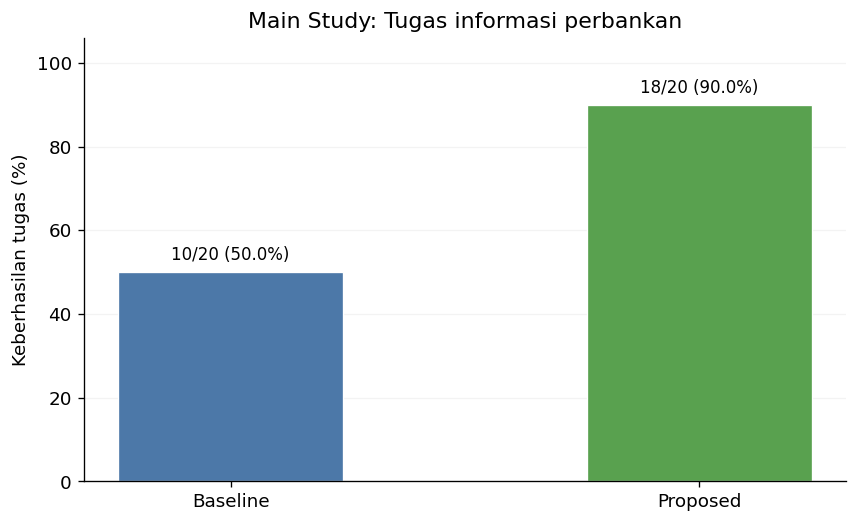

In [35]:
if main is not None:
    row=main_overview.iloc[0]
    bars=pd.DataFrame({'method':['Baseline','Proposed'], 'success':[row.baseline_pct,row.cdea_pct]})
    fig,ax=plt.subplots(figsize=(8.2,4.8))
    plot=ax.bar(bars.method,bars.success,width=.48,
                color=[WARNA_BASELINE, WARNA_PROPOSED], edgecolor='white', linewidth=.8)
    ax.bar_label(plot, labels=[f'{int(row.baseline_n)}/{int(row.pairs)} ({row.baseline_pct:.1f}%)',
                               f'{int(row.cdea_n)}/{int(row.pairs)} ({row.cdea_pct:.1f}%)'],padding=5,fontsize=10)
    ax.set(ylim=(0,106), ylabel='Keberhasilan tugas (%)', title='Main Study: Tugas informasi perbankan')
    ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    save_chart('Gambar_4_1',fig)

### Tabel 4.2 — Hasil Keberhasilan Main Study Berdasarkan Kelompok Tugas

Keberhasilan menurut kategori tugas dan seluruh pasangan valid.

In [36]:
kategori = {'bank_information':'Informasi perbankan',
            'cross_app_workflow':'Lintas aplikasi', 'primitive_control':'Tugas dasar'}
baris_42=[]
for group in ('bank_information','cross_app_workflow','primitive_control'):
    r=main_category.loc[main_category.group.eq(group)].iloc[0]
    baris_42.append({'Kelompok tugas':kategori[group], 'Pasangan':int(r.pairs),
                     'Baseline (%)':r.baseline_pct,'Proposed (%)':r.cdea_pct,
                     'Selisih absolut (%)':r.selisih_abs_persen})
r=main_overview.loc[main_overview.group.eq('All tasks')].iloc[0]
baris_42.append({'Kelompok tugas':'Keseluruhan','Pasangan':int(r.pairs),
                 'Baseline (%)':r.baseline_pct,'Proposed (%)':r.cdea_pct,
                 'Selisih absolut (%)':r.selisih_abs_persen})
tabel_42=pd.DataFrame(baris_42)
simpan_tabel_utama('Tabel_4_2',tabel_42)
tampil_tabel(tabel_42,kolom_persen=['Baseline (%)','Proposed (%)'],
             kolom_selisih=['Selisih absolut (%)'])

,Kelompok tugas,Pasangan,Baseline (%),Proposed (%),Selisih absolut (%)
0,Informasi perbankan,20,"50,00%","90,00%","+40,00%"
1,Lintas aplikasi,72,"48,61%","70,83%","+22,22%"
2,Tugas dasar,36,"77,78%","77,78%","0,00%"
3,Keseluruhan,128,"57,03%","75,78%","+18,75%"


### Gambar 4.2 — Perbandingan Keberhasilan Baseline dan Proposed Berdasarkan Kategori Tugas

Memperlihatkan variasi tingkat keberhasilan pada 3 kelompok tugas.

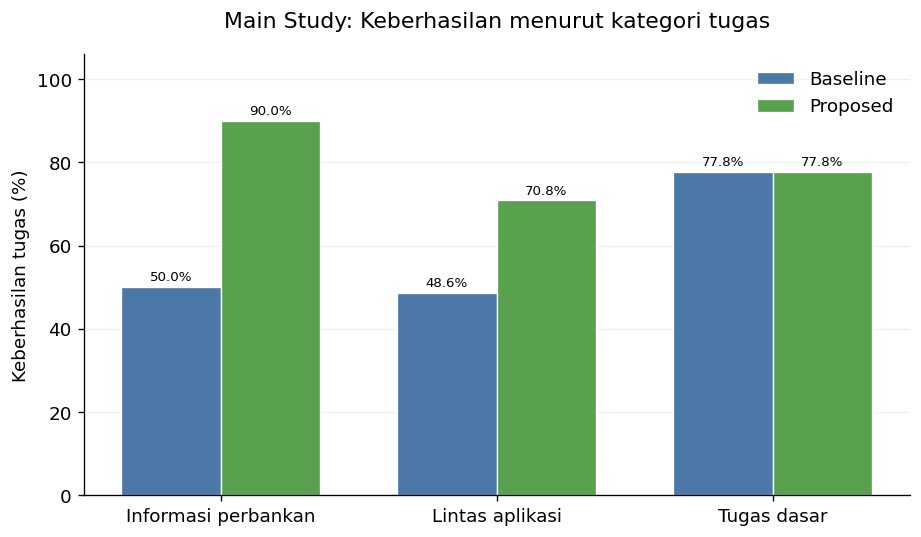

In [37]:
if main is not None:
    category_order=['bank_information','cross_app_workflow','primitive_control']
    categories=main_category.set_index('group').reindex(category_order).reset_index()
    categories['display']=categories['group'].map({'bank_information':'Informasi perbankan', 'cross_app_workflow':'Lintas aplikasi', 'primitive_control':'Tugas dasar'})
    fig=grouped_bars(categories,'display',[('baseline_pct','Baseline'),('cdea_pct','Proposed')],
        'Main Study: Keberhasilan menurut kategori tugas',ylim=(0,106))
    save_chart('Gambar_4_2',fig)

## 03 — Mekanisme CDEA

Meringkas keputusan pencarian yang dapat dibandingkan dan tindakan yang berbeda antar metode.

In [38]:
mechanism_pairs=pd.DataFrame()
mechanism_by_divergence=pd.DataFrame()
trace_by_method=pd.DataFrame()
trace_examples=pd.DataFrame()
enriched_episodes={}
mechanism_rows=[]; diverge_rows=[]; trace_rows=[]; example_rows=[]

for study_name, study in SOURCES.items():
    if study is None: continue
    pairs=study['valid'].copy()
    raw=study['episodes'].copy()
    # Main has pair-level metrics duplicated across arms in results.csv; deduplicate by pair ID.
    if 'comparable_probe_decisions' not in pairs:
        for key in ('comparable_probe_decisions','policy_action_divergences'):
            if key in raw:
                once=raw.groupby('pair_id')[key].max().rename(key)
                pairs=pairs.merge(once,left_on='pair_id',right_index=True,how='left')
    for key in ('comparable_probe_decisions','policy_action_divergences'):
        if key not in pairs:pairs[key]=np.nan
        pairs[key]=pd.to_numeric(pairs[key],errors='coerce')
    measured=pairs['comparable_probe_decisions'].notna() & pairs['policy_action_divergences'].notna()
    mechanism_rows.append({'study':study_name,'valid_pairs':len(pairs),
        'pairs_with_diagnostics':int(measured.sum()),
        'pairs_with_comparable_decisions':int(pairs.comparable_probe_decisions.gt(0).sum()),
        'comparable_decisions_total':int(pairs.comparable_probe_decisions.fillna(0).sum()),
        'pairs_with_action_divergence':int(pairs.policy_action_divergences.gt(0).sum()),
        'divergent_decisions_total':int(pairs.policy_action_divergences.fillna(0).sum())})
    if measured.any():
        pairs['divergence_observed']=pairs.policy_action_divergences.gt(0)
        for has_div, group in pairs.loc[measured].groupby('divergence_observed'):
            diverge_rows.append({'study':study_name,'action_divergence':bool(has_div),**paired_stats(group)})

    # Use actual stored trace events (and preserve missing-trace counts).
    available=set()
    with zipfile.ZipFile(study['path']) as z:
        available=set(z.namelist())
        for _,ep_row in raw.iterrows():
            if ep_row.pair_id not in set(pairs.pair_id):continue
            rel=ep_row.get('episode_artifact')
            if not isinstance(rel,str) or not rel.endswith('/episode.json'):
                rel=f'episodes/{ep_row.pair_id}/{ep_row.method}/episode/episode.json'
            archive_entry=study['prefix']+rel.lstrip('/')
            item={'study':study_name,'pair_id':ep_row.pair_id,'method':ep_row.method,
                  'stratum':ep_row.stratum,'model_label':ep_row.model_label,
                  'official_success':bool(ep_row.official_success_raw),
                  'trace_available':False,'trace_steps':np.nan,'opportunity_steps':np.nan,
                  'selected_probe_steps':np.nan,'candidate_probes_seen':np.nan,
                  'override_steps':np.nan,'grounded_evidence_entries':np.nan,
                  'resolved_ledger_steps':np.nan,'repair_requests':np.nan,
                  'end_reason':ep_row.get('end_reason','unknown'),
                  'total_seconds_from_trace':np.nan}
            if archive_entry in available:
                ep=json.loads(z.read(archive_entry))
                trace=ep.get('trace')
                if isinstance(trace,list):
                    item['trace_available']=True
                    item['trace_steps']=len(trace)
                    item['opportunity_steps']=0
                    item['selected_probe_steps']=0
                    item['candidate_probes_seen']=0
                    item['override_steps']=0
                    item['grounded_evidence_entries']=0
                    item['resolved_ledger_steps']=0
                    for step in trace:
                        if not isinstance(step,dict):continue
                        item['opportunity_steps']+=int(bool(step.get('probe_opportunity')))
                        item['selected_probe_steps']+=int(bool(step.get('selected_probe')))
                        item['candidate_probes_seen']+=len(step.get('candidate_probes') or [])
                        item['override_steps']+=int(bool(step.get('policy_overrode_primary')))
                        observations=step.get('grounded_tentative_evidence') or []
                        item['grounded_evidence_entries']+=len(observations)
                        ledger=step.get('ledger') or {}
                        item['resolved_ledger_steps']+=int(any(
                            isinstance(v,dict) and str(v.get('state','')).upper() in ('SATISFIED','REFUTED')
                            for v in ledger.values()))
                        if step.get('selected_probe') and len(example_rows)<200:
                            selected=step['selected_probe'] or {}
                            example_rows.append({'study':study_name,'pair_id':ep_row.pair_id,
                                'method':ep_row.method,'task_id':f'{ep_row.task_group}/{ep_row.task}',
                                'step':step.get('step'),'selected_bid':selected.get('bid'),
                                'may_answer':','.join(selected.get('may_answer',[])),
                                'candidate_count':len(step.get('candidate_probes') or []),
                                'policy_override':bool(step.get('policy_overrode_primary')),
                                'tentative_evidence_entries':len(observations)})
                    item['repair_requests']=ep.get('repair_requests')
                    item['end_reason']=ep.get('end_reason') or item['end_reason']
                    item['total_seconds_from_trace']=ep.get('total_seconds')
            trace_rows.append(item)
    enriched_episodes[study_name]=raw.merge(
        pd.DataFrame([r for r in trace_rows if r['study']==study_name]),
        on=['pair_id','method','model_label','stratum'],how='left',suffixes=('','_trace'))

mechanism_pairs=pd.DataFrame(mechanism_rows)
mechanism_by_divergence=pd.DataFrame(diverge_rows)
trace_by_method=pd.DataFrame(trace_rows)
trace_examples=pd.DataFrame(example_rows)
trace_report=(trace_by_method.groupby(['study','method'],as_index=False).agg(
    episode_rows=('pair_id','size'), traces_present=('trace_available','sum'),
    trace_steps=('trace_steps','sum'),opportunity_steps=('opportunity_steps','sum'),
    selected_probe_steps=('selected_probe_steps','sum'),
    tentative_evidence_entries=('grounded_evidence_entries','sum'),
    resolved_ledger_steps=('resolved_ledger_steps','sum'))) if not trace_by_method.empty else pd.DataFrame()
for key,obj in [('14_mechanism_pairs',mechanism_pairs),('15_mechanism_by_divergence',mechanism_by_divergence),
                ('16_trace_indicators',trace_report),('17_probe_examples',trace_examples)]:
    record_table(key,obj)

### Tabel 4.3 — Ringkasan Keputusan Pencarian Informasi

In [39]:
baris_43 = [
    ('Pasangan valid', 'valid_pairs'),
    ('Pasangan dengan keputusan sebanding', 'pairs_with_comparable_decisions'),
    ('Jumlah keputusan sebanding', 'comparable_decisions_total'),
    ('Pasangan dengan perbedaan tindakan', 'pairs_with_action_divergence'),
    ('Jumlah keputusan berbeda', 'divergent_decisions_total'),
]
m_main=mechanism_pairs.loc[mechanism_pairs.study.eq('Main Large')].iloc[0]
m_small=mechanism_pairs.loc[mechanism_pairs.study.eq('Scale Small')].iloc[0]
tabel_43 = pd.DataFrame([{'Indikator':label,'Main Study':int(m_main[col]),
                          'Small-Model Extension':int(m_small[col])} for label,col in baris_43])
simpan_tabel_utama('Tabel_4_3',tabel_43)
tampil_tabel(tabel_43)

,Indikator,Main Study,Small-Model Extension
0,Pasangan valid,128,128
1,Pasangan dengan keputusan sebanding,48,75
2,Jumlah keputusan sebanding,48,75
3,Pasangan dengan perbedaan tindakan,33,49
4,Jumlah keputusan berbeda,33,49


### Gambar 4.3 — Perbandingan Keputusan Pencarian Informasi pada Main Study

Jumlah pasangan dengan keputusan sebanding dan tindakan yang berbeda.

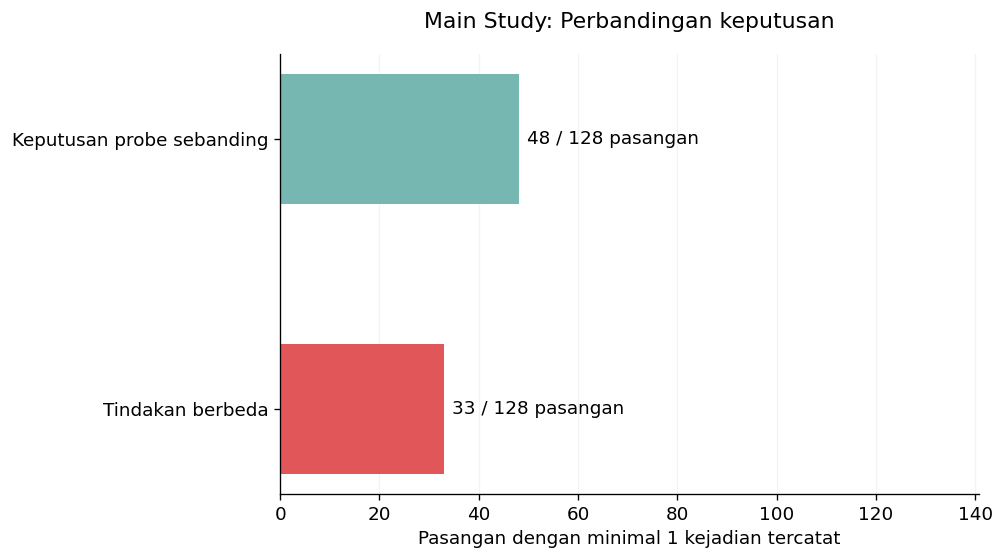

In [40]:
study_name = 'Main Large'
if study_name in mechanism_pairs.study.values:
    row=mechanism_pairs.loc[mechanism_pairs.study==study_name].iloc[0]
    names=['Keputusan probe sebanding','Tindakan berbeda']
    values=[row.pairs_with_comparable_decisions,row.pairs_with_action_divergence]
    fig,ax=plt.subplots(figsize=(8.5,4.8))
    bars=ax.barh(names, values, height=.48, color=[WARNA_TAMBAHAN_1, WARNA_TAMBAHAN_2])
    ax.bar_label(bars, labels=[f'{int(v)} / {int(row.valid_pairs)} pasangan' for v in values],padding=5)
    ax.set_xlim(0,max(int(row.valid_pairs)*1.10,max(values)*1.25,1))
    ax.set_xlabel('Pasangan dengan minimal 1 kejadian tercatat')
    ax.set_title('Main Study: Perbandingan keputusan',pad=16)
    ax.invert_yaxis();ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout()
    save_chart('Gambar_4_3',fig)

### Gambar 4.4 — Perbandingan Keputusan Pencarian Informasi pada Small-Model Extension

Memperlihatkan metrik keputusan yang sama pada kelompok model kecil.

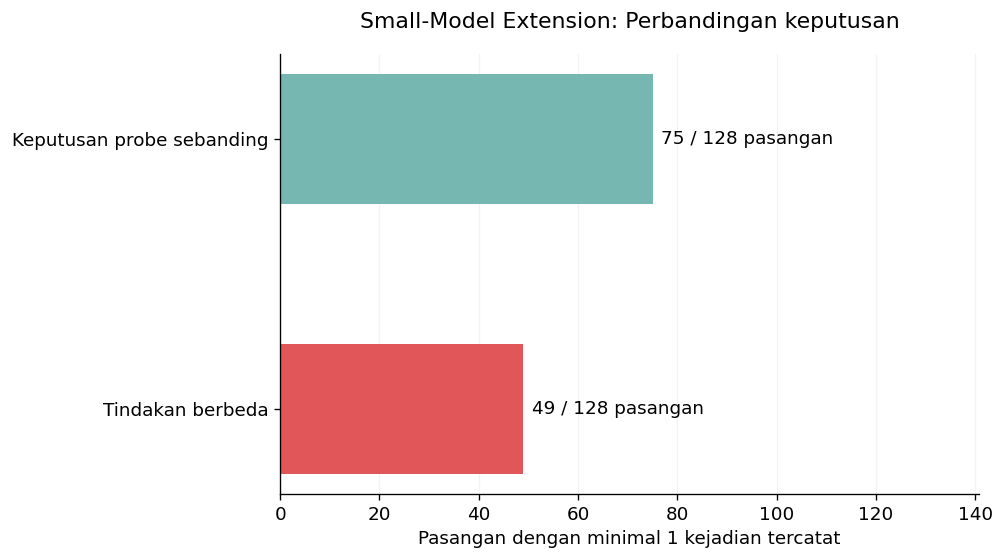

In [41]:
study_name = 'Scale Small'
if study_name in mechanism_pairs.study.values:
    row=mechanism_pairs.loc[mechanism_pairs.study==study_name].iloc[0]
    names=['Keputusan probe sebanding','Tindakan berbeda']
    values=[row.pairs_with_comparable_decisions,row.pairs_with_action_divergence]
    fig,ax=plt.subplots(figsize=(8.5,4.8))
    bars=ax.barh(names, values, height=.48, color=[WARNA_TAMBAHAN_1, WARNA_TAMBAHAN_2])
    ax.bar_label(bars, labels=[f'{int(v)} / {int(row.valid_pairs)} pasangan' for v in values],padding=5)
    ax.set_xlim(0,max(int(row.valid_pairs)*1.10,max(values)*1.25,1))
    ax.set_xlabel('Pasangan dengan minimal 1 kejadian tercatat')
    ax.set_title('Small-Model Extension: Perbandingan keputusan',pad=16)
    ax.invert_yaxis();ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout()
    save_chart('Gambar_4_4',fig)

## 04 — Efisiensi Pelaksanaan
Selisih tindakan dan durasi dihitung sebagai *Proposed − Baseline*. Nilai negatif berarti penggunaan yang lebih kecil pada *Proposed*.

In [42]:
paired_resources=pd.DataFrame()
resource_by_method=pd.DataFrame()
end_reasons=pd.DataFrame()
resource_rows=[]; method_rows=[]; failure_rows=[]; pair_steps={}
for study_name, study in SOURCES.items():
    if study is None:continue
    episode=enriched_episodes[study_name].copy()
    valid_ids=set(study['valid'].pair_id)
    episode=episode[episode.pair_id.isin(valid_ids)].copy()
    metric_alias={'steps':'steps','model_calls':'model_calls','model_seconds':'model_seconds',
                  'total_seconds':'total_seconds','repair_requests':'repair_requests'}
    if 'total_seconds' not in episode:
        episode['total_seconds']=episode.total_seconds_from_trace
    if 'repair_requests' not in episode:
        episode['repair_requests']=episode.repair_requests_trace if 'repair_requests_trace' in episode else np.nan
    if 'repair_requests' in episode and 'repair_requests_trace' in episode:
        episode['repair_requests']=pd.to_numeric(episode.repair_requests,errors='coerce').fillna(
            pd.to_numeric(episode.repair_requests_trace,errors='coerce'))
    for field in metric_alias:
        if field in episode:episode[field]=pd.to_numeric(episode[field],errors='coerce')
    for method,group in episode.groupby('method'):
        for metric in metric_alias:
            if metric not in group:continue
            arr=group[metric].dropna()
            if len(arr):
                method_rows.append({'study':study_name,'method':method,'metric':metric,
                                    'n':len(arr),'mean':arr.mean(),'median':arr.median()})
        failures=group.loc[group.official_success_raw.ne(True)]
        for reason,count in failures.end_reason.fillna('unknown').value_counts().items():
            failure_rows.append({'study':study_name,'method':method,
                                 'end_reason':reason,'unsuccessful_episodes':int(count)})
    for metric in metric_alias:
        if metric not in episode:continue
        pivot=episode.pivot(index='pair_id',columns='method',values=metric)
        if not {'Baseline','Proposed'}.issubset(pivot.columns):continue
        joined=(pivot.Proposed-pivot.Baseline).dropna()
        both=study['valid'].loc[study['valid'].baseline_success.eq(True) &
                                study['valid'].proposed_success.eq(True),'pair_id']
        for population,index in [('Semua valid',joined.index),
                                 ('Keduanya berhasil',joined.index.intersection(both))]:
            diff=joined.loc[index]
            if len(diff):
                resource_rows.append({'study':study_name,'population':population,'metric':metric,
                                      'matched_pairs':len(diff),'median_cdea_minus_baseline':diff.median(),
                                      'mean_cdea_minus_baseline':diff.mean()})
        if metric=='steps':
            pair_steps[study_name]={'all':joined,'both':joined.loc[joined.index.intersection(both)]}

paired_resources=pd.DataFrame(resource_rows)
resource_by_method=pd.DataFrame(method_rows)
end_reasons=pd.DataFrame(failure_rows)
record_table('18_paired_efficiency',paired_resources)
record_table('19_efficiency_by_method',resource_by_method)
record_table('20_failure_end_reasons',end_reasons)

### Tabel 4.4 — Perbandingan Efisiensi Pelaksanaan

In [43]:
baris_44=[]
for studi,label in [('Main Large','Main Study'),('Scale Small','Model kecil')]:
    for populasi,deskripsi in [('Semua valid','Seluruh pasangan valid'),('Keduanya berhasil','Keduanya berhasil')]:
        subset = paired_resources.loc[(paired_resources.study.eq(studi)) &
                                       (paired_resources.population.eq(populasi))]
        s = subset.loc[subset.metric.eq('steps')].iloc[0]
        t = subset.loc[subset.metric.eq('total_seconds')].iloc[0]
        baris_44.append({'Kelompok':label,'Kondisi':deskripsi,
                        'Pasangan':int(s.matched_pairs),
                        'Selisih tindakan':float(s.mean_cdea_minus_baseline),
                        'Selisih durasi (detik)':float(t.mean_cdea_minus_baseline)})
tabel_44 = pd.DataFrame(baris_44)
simpan_tabel_utama('Tabel_4_4', tabel_44)
tampil_tabel(tabel_44,kolom_desimal=['Selisih tindakan','Selisih durasi (detik)'])

,Kelompok,Kondisi,Pasangan,Selisih tindakan,Selisih durasi (detik)
0,Main Study,Seluruh pasangan valid,128,"-0,52","-2,96"
1,Main Study,Keduanya berhasil,72,"-0,19","-1,30"
2,Model kecil,Seluruh pasangan valid,128,"-1,63","-6,99"
3,Model kecil,Keduanya berhasil,33,"+0,06","+1,14"


### Gambar 4.5 — Selisih Rata-Rata Jumlah Tindakan pada Main Study

Membandingkan seluruh pasangan valid dan pasangan ketika kedua metode berhasil.

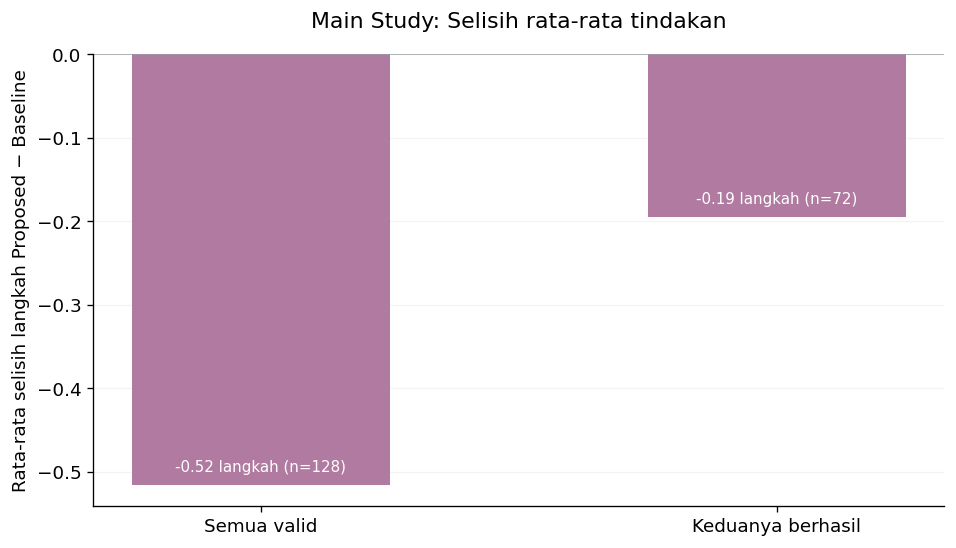

In [44]:
study_name = 'Main Large'
if study_name in paired_resources.study.values:
    subset=paired_resources[(paired_resources.study==study_name)&(paired_resources.metric=='steps')]
    if subset.empty:raise ValueError('Missing steps for requested study')
    subset=subset.set_index('population').reindex(['Semua valid','Keduanya berhasil']).dropna(subset=['mean_cdea_minus_baseline'])
    if subset.empty:raise ValueError('Missing steps for requested study')
    fig,ax=plt.subplots(figsize=(8.1,4.7))
    bars=ax.bar(subset.index, subset.mean_cdea_minus_baseline, width=.5, color=WARNA_LARGE)
    for bar, (_,row) in zip(bars,subset.iterrows()):
        y=bar.get_height()
        ax.annotate(f'{y:+.2f} langkah (n={int(row.matched_pairs)})',
                    (bar.get_x()+bar.get_width()/2,y),xytext=(0,5 if y>=0 else 8),
                    textcoords='offset points',ha='center',fontsize=9,
                    color='white' if y<0 else 'black')
    ax.axhline(0, color='#9AA0A6', lw=.9)
    ax.set_ylabel('Rata-rata selisih langkah Proposed − Baseline')
    ax.set_title('Main Study: Selisih rata-rata tindakan',pad=16)
    ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout()
    save_chart('Gambar_4_5',fig)

### Gambar 4.6 — Selisih Rata-Rata Jumlah Tindakan pada Small-Model Extension

Analisis efisiensi pada kelompok model kecil.

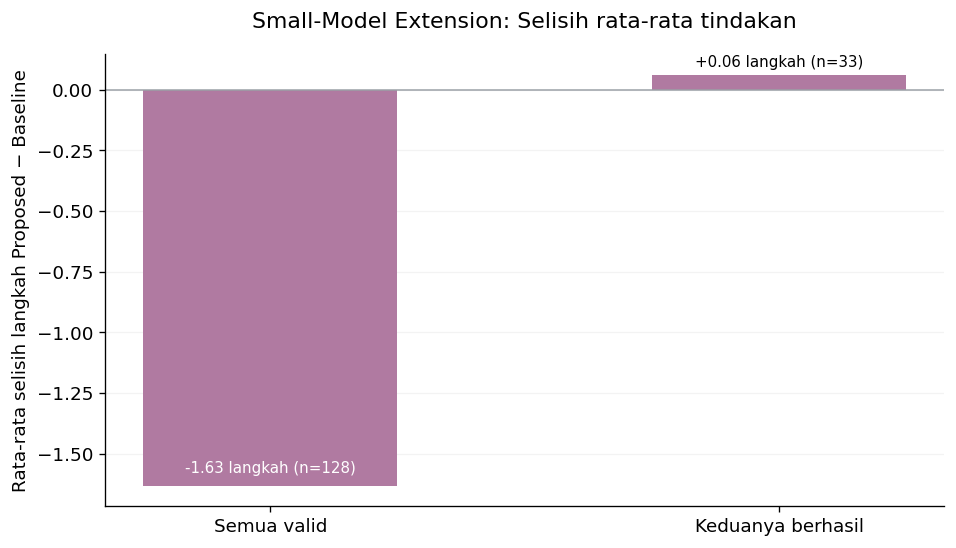

In [45]:
study_name = 'Scale Small'
if study_name in paired_resources.study.values:
    subset=paired_resources[(paired_resources.study==study_name)&(paired_resources.metric=='steps')]
    if subset.empty:raise ValueError('Missing steps for requested study')
    subset=subset.set_index('population').reindex(['Semua valid','Keduanya berhasil']).dropna(subset=['mean_cdea_minus_baseline'])
    if subset.empty:raise ValueError('Missing steps for requested study')
    fig,ax=plt.subplots(figsize=(8.1,4.7))
    bars=ax.bar(subset.index, subset.mean_cdea_minus_baseline, width=.5, color=WARNA_LARGE)
    for bar, (_,row) in zip(bars,subset.iterrows()):
        y=bar.get_height()
        ax.annotate(f'{y:+.2f} langkah (n={int(row.matched_pairs)})',
                    (bar.get_x()+bar.get_width()/2,y),xytext=(0,5 if y>=0 else 8),
                    textcoords='offset points',ha='center',fontsize=9,
                    color='white' if y<0 else 'black')
    ax.axhline(0, color='#9AA0A6', lw=.9)
    ax.set_ylabel('Rata-rata selisih langkah Proposed − Baseline')
    ax.set_title('Small-Model Extension: Selisih rata-rata tindakan',pad=16)
    ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout()
    save_chart('Gambar_4_6',fig)

## 05 — Small-Model Extension

Hasil pada 4 model kecil; tingkat keberhasilan dihitung dari pasangan valid.

In [46]:
scale_overview=pd.DataFrame()
scale_models=pd.DataFrame()
if scale is not None:
    df=scale['valid']
    summaries=[summarize('Derived comparison','All models',df)]
    summaries.extend(summarize('Derived comparison','Size: '+s,group) for s,group in df.groupby('size'))
    scale_overview=pd.DataFrame(summaries)
    scale_models=pd.DataFrame([{'model_label':k,'size':grp['size'].iloc[0],**paired_stats(grp)}
        for k,grp in df.groupby('model_label')]).sort_values(['size','model_label'])
    record_table('07_derived_size_overview',scale_overview)
    record_table('08_derived_eight_models',scale_models)
else:
    print('Diperlukan 2 ZIP sumber untuk perbandingan ukuran model.')


In [47]:
scale_categories=pd.DataFrame()
shared_model_context=pd.DataFrame()
if scale is not None:
    df=scale['valid']
    scale_categories=pd.DataFrame([{'stratum':st,'size':sz,**paired_stats(grp)}
        for (st,sz),grp in df.groupby(['stratum','size'])]).sort_values(['stratum','size'])
    record_table('09_derived_task_category_size',scale_categories)
    if not source_mapping.empty:
        shared_model_context=source_mapping.copy()
        record_table('10_model_source_mapping',shared_model_context)


### Tabel 4.5 — Hasil Keberhasilan Small-Model Extension

In [48]:
nama_model={'qwen3.5-4b':'Qwen3.5-4B','ministral3-3b':'Ministral3-3B',
            'granite4.1-3b':'Granite4.1-3B','xlam2-3b':'xLAM2-3B'}
baris_45=[]
for key in ('qwen3.5-4b','ministral3-3b','granite4.1-3b','xlam2-3b'):
    r=scale_models.loc[scale_models.model_label.eq(key)].iloc[0]
    baris_45.append({'Model':nama_model[key], 'Baseline (%)':r.baseline_pct,
                     'Proposed (%)':r.cdea_pct, 'Selisih absolut (%)':r.selisih_abs_persen})
r=scale_overview.loc[scale_overview.group.eq('Size: small')].iloc[0]
baris_45.append({'Model':'Keseluruhan','Baseline (%)':r.baseline_pct,
                 'Proposed (%)':r.cdea_pct,'Selisih absolut (%)':r.selisih_abs_persen})
tabel_45=pd.DataFrame(baris_45)
simpan_tabel_utama('Tabel_4_5',tabel_45)
tampil_tabel(tabel_45,kolom_persen=['Baseline (%)','Proposed (%)'],
             kolom_selisih=['Selisih absolut (%)'])


,Model,Baseline (%),Proposed (%),Selisih absolut (%)
0,Qwen3.5-4B,"43,75%","53,13%","+9,38%"
1,Ministral3-3B,"34,38%","50,00%","+15,63%"
2,Granite4.1-3B,"31,25%","40,63%","+9,38%"
3,xLAM2-3B,"25,00%","25,00%","0,00%"
4,Keseluruhan,"33,59%","42,19%","+8,59%"


## 06 — Perbandingan Ukuran Model
Kelompok Large diambil dari Main Study dan Small dari Scale. Hasil keduanya dibandingkan pada tugas yang sama.

### Gambar 4.7 — Perbandingan Tingkat Keberhasilan Baseline dan Proposed pada 8 Model

Menampilkan persentase keberhasilan pada seluruh model yang diuji.

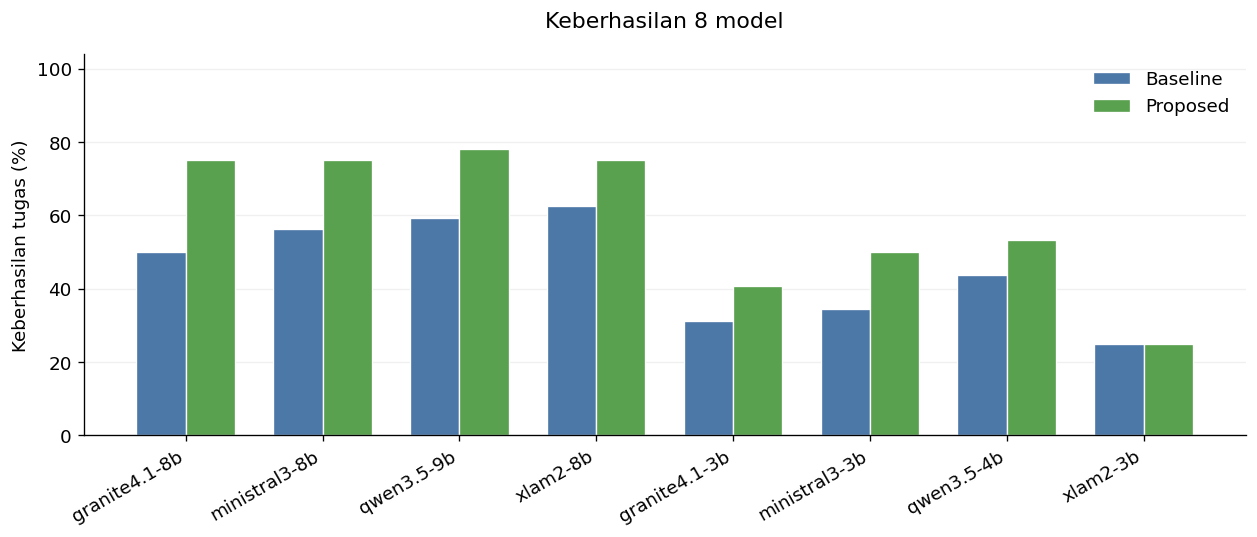

In [49]:
if scale is not None:
    s=scale_models.sort_values(['size','model_label']).copy()
    fig=grouped_bars(s,'model_label',[('baseline_pct','Baseline'),('cdea_pct','Proposed')],
                     'Keberhasilan 8 model',rotation=30,ylim=(0,104))
    save_chart('Gambar_4_7',fig)


### Tabel 4.6 — Hasil Baseline dan Proposed (CDEA) pada Setiap Model

Menampilkan hasil delapan model (empat Large dan empat Small) berdasarkan 32 pasangan pengujian per model, beserta selisih tingkat keberhasilannya.

In [50]:
# Tabel 4.6 — Hasil Baseline dan Proposed (CDEA) pada Setiap Model

nama_model_46 = {
    'qwen3.5-9b': 'Qwen3.5-9B',
    'ministral3-8b': 'Ministral3-8B',
    'granite4.1-8b': 'Granite4.1-8B',
    'xlam2-8b': 'xLAM2-8B',
    'qwen3.5-4b': 'Qwen3.5-4B',
    'ministral3-3b': 'Ministral3-3B',
    'granite4.1-3b': 'Granite4.1-3B',
    'xlam2-3b': 'xLAM2-3B'
}

urutan_model_46 = [
    'qwen3.5-9b',
    'ministral3-8b',
    'granite4.1-8b',
    'xlam2-8b',
    'qwen3.5-4b',
    'ministral3-3b',
    'granite4.1-3b',
    'xlam2-3b'
]

baris_46 = []

for key in urutan_model_46:
    r = scale_models.loc[
        scale_models.model_label.eq(key)
    ].iloc[0]

    baris_46.append({
        'Ukuran model': 'Large (8B–9B)' if r['size'] == 'large' else 'Small (3B–4B)',
        'Model': nama_model_46[key],
        'Pasangan': int(r['pairs']),
        'Baseline (n)': int(r['baseline_n']),
        'Baseline (%)': r['baseline_pct'],
        'Proposed (n)': int(r['cdea_n']),
        'Proposed (%)': r['cdea_pct'],
        'Selisih absolut (%)': r['selisih_abs_persen']
    })

tabel_46 = pd.DataFrame(baris_46)

simpan_tabel_utama('Tabel_4_6', tabel_46)

tampil_tabel(
    tabel_46,
    kolom_persen=['Baseline (%)', 'Proposed (%)'],
    kolom_selisih=['Selisih absolut (%)']
)

,Ukuran model,Model,Pasangan,Baseline (n),Baseline (%),Proposed (n),Proposed (%),Selisih absolut (%)
0,Large (8B–9B),Qwen3.5-9B,32,19,"59,38%",25,"78,13%","+18,75%"
1,Large (8B–9B),Ministral3-8B,32,18,"56,25%",24,"75,00%","+18,75%"
2,Large (8B–9B),Granite4.1-8B,32,16,"50,00%",24,"75,00%","+25,00%"
3,Large (8B–9B),xLAM2-8B,32,20,"62,50%",24,"75,00%","+12,50%"
4,Small (3B–4B),Qwen3.5-4B,32,14,"43,75%",17,"53,13%","+9,38%"
5,Small (3B–4B),Ministral3-3B,32,11,"34,38%",16,"50,00%","+15,63%"
6,Small (3B–4B),Granite4.1-3B,32,10,"31,25%",13,"40,63%","+9,38%"
7,Small (3B–4B),xLAM2-3B,32,8,"25,00%",8,"25,00%","0,00%"


### Gambar 4.8 — Perbandingan Manfaat CDEA pada Model Large dan Small

Menampilkan selisih keberhasilan Proposed terhadap Baseline pada kedua kelompok ukuran model.

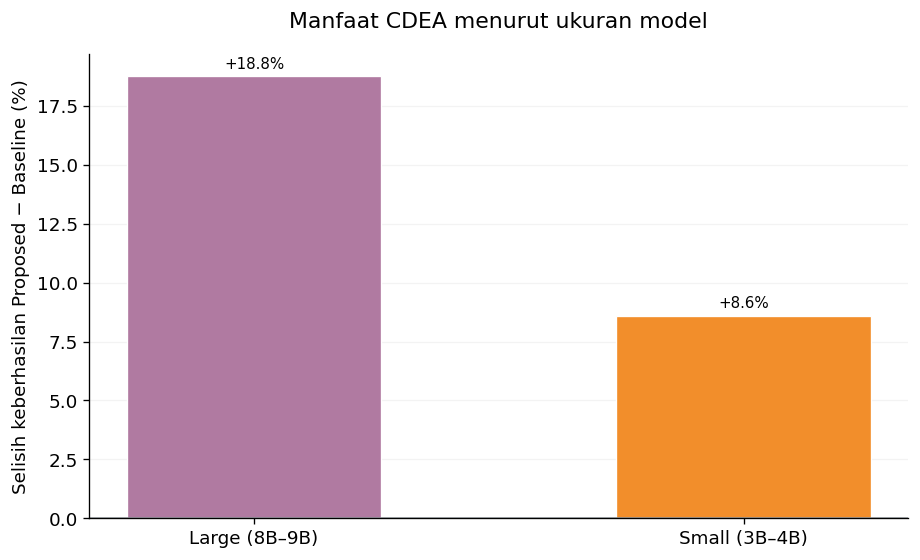

In [51]:
if scale is not None:
    rows=[]
    for ukuran,label in [('large','Large (8B–9B)'),('small','Small (3B–4B)')]:
        r=scale_overview.loc[scale_overview.group.eq('Size: '+ukuran)].iloc[0]
        rows.append({'Ukuran model':label,'Selisih absolut (%)':r.selisih_abs_persen})
    d=pd.DataFrame(rows)
    fig,ax=plt.subplots(figsize=(7.8,4.8))
    bars=ax.bar(d['Ukuran model'],d['Selisih absolut (%)'],width=.52,
                color=[WARNA_LARGE,WARNA_SMALL],edgecolor='white',linewidth=.8)
    ax.bar_label(bars,fmt='%+.1f%%',fontsize=9,padding=3)
    ax.set_ylabel('Selisih keberhasilan Proposed − Baseline (%)')
    ax.set_title('Manfaat CDEA menurut ukuran model',pad=16)
    ax.axhline(0,color='#9AA0A6',lw=.9)
    ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout()
    save_chart('Gambar_4_8',fig)


### Gambar 4.9 — Variasi Selisih Keberhasilan Berdasarkan Kategori Tugas dan Ukuran Model

Membandingkan besarnya manfaat pada 3 kelompok tugas.

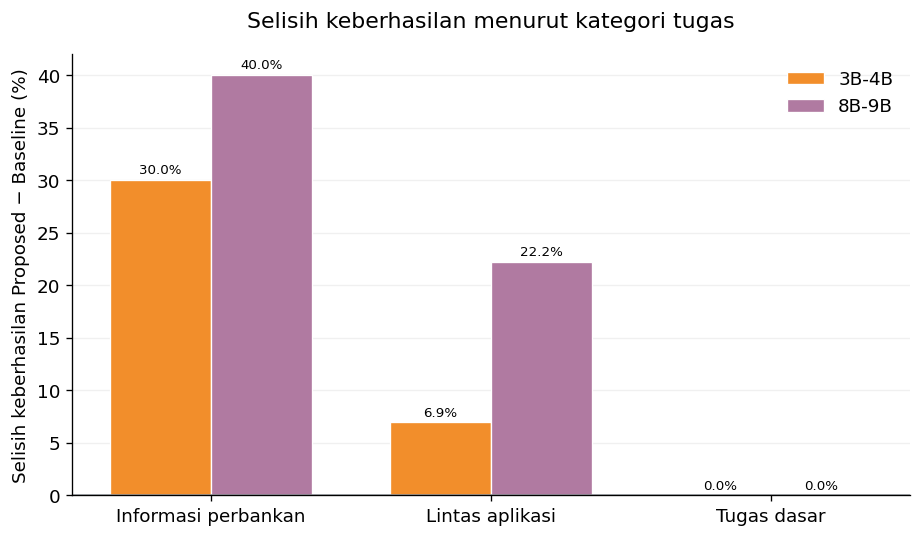

In [52]:
if scale is not None:
    order=['bank_information','cross_app_workflow','primitive_control']
    chart=scale_categories.pivot(index='stratum',columns='size',values='selisih_abs_persen').reindex(order)
    d=pd.DataFrame({'category':[{'bank_information':'Informasi perbankan','cross_app_workflow':'Lintas aplikasi','primitive_control':'Tugas dasar'}[s] for s in order],
                    'small':chart['small'].to_numpy(),'large':chart['large'].to_numpy()})
    fig=grouped_bars(d,'category',[('small','3B-4B'),('large','8B-9B')],
        'Selisih keberhasilan menurut kategori tugas',
        ylabel='Selisih keberhasilan Proposed − Baseline (%)',
        warna=[WARNA_SMALL, WARNA_LARGE])
    save_chart('Gambar_4_9',fig)

## 07 — Ringkasan Hasil dan Statistik

Meringkas hasil utama untuk 3 rumusan masalah, berikut uji *exact McNemar* dan interval bootstrap berbasis tugas.

In [53]:
stat_rows = []
for label, frame in [
    ('Main — informasi perbankan', main['valid'].loc[main['valid'].stratum.eq('bank_information')]),
    ('Main — semua tugas', main['valid']),
    ('Small — semua tugas', small['valid'])
]:
    s = paired_stats(frame)
    stat_rows.append({'Kelompok':label, 'Pasangan':s['pairs'], 'Baseline (%)':s['baseline_pct'],
        'Proposed (%)':s['cdea_pct'], 'Selisih absolut (%)':s['selisih_abs_persen'],
        'p McNemar':s['mcnemar_p'], 'Interval bawah (%)':s['task_ci_low'], 'Interval atas (%)':s['task_ci_high']})
statistik = pd.DataFrame(stat_rows)
record_table('21_ringkasan_statistik',statistik)
tampil = statistik.copy()
tampil['p McNemar'] = tampil['p McNemar'].map(lambda x: '<0,001' if x < .001 else f'{x:.3f}'.replace('.',','))
display(tampil.round(2))

,Kelompok,Pasangan,Baseline (%),Proposed (%),Selisih absolut (%),p McNemar,Interval bawah (%),Interval atas (%)
0,Main — informasi perbankan,20,50.00,90.00,40.00,"0,021",15.00,60.00
1,Main — semua tugas,128,57.03,75.78,18.75,"<0,001",9.38,29.69
2,Small — semua tugas,128,33.59,42.19,8.59,"0,071",0.00,17.97


In [54]:
from IPython.display import Markdown
utama = paired_stats(main['valid'].loc[main['valid'].stratum.eq('bank_information')])
large_result = paired_stats(main['valid'])
small_result = paired_stats(small['valid'])
m_main = mechanism_pairs.loc[mechanism_pairs.study.eq('Main Large')].iloc[0]
def persen(x): return f'{x:.2f}%'.replace('.', ',')
display(Markdown(
    f"**1. Keberhasilan tugas.** Informasi perbankan: Baseline {persen(utama['baseline_pct'])}, "
    f"Proposed {persen(utama['cdea_pct'])}.\n\n"
    f"**2. Keputusan CDEA.** Pada Main, {int(m_main.pairs_with_comparable_decisions)} pasangan "
    f"memiliki keputusan sebanding dan {int(m_main.pairs_with_action_divergence)} pasangan "
    f"menunjukkan tindakan berbeda.\n\n"
    f"**3. Ukuran model.** Selisih hasil Large {persen(large_result['selisih_abs_persen'])}; "
    f"Small {persen(small_result['selisih_abs_persen'])}."
))

**1. Keberhasilan tugas.** Informasi perbankan: Baseline 50,00%, Proposed 90,00%.

**2. Keputusan CDEA.** Pada Main, 48 pasangan memiliki keputusan sebanding dan 33 pasangan menunjukkan tindakan berbeda.

**3. Ukuran model.** Selisih hasil Large 18,75%; Small 8,59%.

## 08 — Ekspor Hasil

Ekspor **6 tabel utama** ke `tables/`, **9 grafik** ke `figures/`, dan CSV perhitungan terperinci ke `detailed_analysis/`. Metadata serta ringkasan statistik berada di `summary/`.

In [55]:
from pathlib import Path
import zipfile

# Setiap tabel CSV utama tetap numerik agar bisa dianalisis ulang.
DETAIL = ROOT / 'detailed_analysis'
SUM = ROOT / 'summary'
DETAIL.mkdir(parents=True, exist_ok=True)
SUM.mkdir(parents=True, exist_ok=True)

# Ekspor tabel utama.
for nama, tabel in TABEL_UTAMA.items():
    tabel.to_csv(
        TAB / (nama + '.csv'),
        index=False,
        float_format='%.8f'
    )

# Ekspor tabel analisis rinci.
for nama, data in TABLES.items():
    data.to_csv(
        DETAIL / (nama + '.csv'),
        index=False,
        float_format='%.8g'
    )

# Ekspor ringkasan statistik.
statistik.to_csv(
    SUM / 'ringkasan_statistik.csv',
    index=False,
    float_format='%.8g'
)

# Pastikan seluruh tabel dan gambar utama tersedia dalam urutan yang benar.
urutan_gambar = [x.stem for x in FIGURES]
urutan_harus = [f'Gambar_4_{i}' for i in range(1, 10)]

assert urutan_gambar == urutan_harus, (urutan_gambar, urutan_harus)
assert list(TABEL_UTAMA) == [f'Tabel_4_{i}' for i in range(1, 7)]

# README singkat untuk keluaran analisis.
(ROOT / 'README.txt').write_text(
    'HASIL ANALISIS CDEA — BAB IV\n'
    '9 gambar berwarna Gambar_4_1 sampai Gambar_4_9 di figures/.\n'
    '6 tabel utama Tabel_4_1 sampai Tabel_4_6 di tables/.\n'
    'Analisis rinci tersedia di detailed_analysis/.\n'
    'Ringkasan statistik tersedia di summary/.\n'
    'Sumber data: main_observation.zip dan scale_reference.zip, tidak diedit.\n'
    'Data Small menggunakan bagian Small dari Scale Study; data Large dari '
    'Scale Study tidak dihitung ulang.\n',
    encoding='utf-8'
)

# Paketkan seluruh hasil analisis.
zip_hasil = Path.cwd() / 'Hasil_Analisis_CDEA_Bab_IV_Terurut.zip'

with zipfile.ZipFile(
    zip_hasil,
    'w',
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as z:
    for path in sorted(ROOT.rglob('*')):
        if path.is_file():
            z.write(
                path,
                arcname='Hasil_Analisis_CDEA/' + str(path.relative_to(ROOT))
            )

print(
    f'Ekspor selesai: {len(TABEL_UTAMA)} tabel utama, '
    f'{len(TABLES)} tabel rinci, '
    f'{len(FIGURES)} grafik berwarna.'
)
print('File ZIP:', zip_hasil.resolve())

Ekspor selesai: 6 tabel utama, 20 tabel rinci, 9 grafik berwarna.
File ZIP: /content/Hasil_Analisis_CDEA_Bab_IV_Terurut.zip
